# LLM index

In [1]:
import torch
import math
import random
import colorsys
import matplotlib.pyplot as plt
from datetime import timedelta

from llm_index.data import load_data
from llm_index.compute import fit
from llm_index.distribution import cumulative_normal, cumulative_split_normal, inverse_cumulative_split_normal

### Data

In [2]:
data = load_data()

print(f"{len(data.models)} models, {len(data.benchmarks)} benchmarks, {len(data.milestones)} milestones, {len(data.get_benchmark_results())} benchmark results, {len(data.get_milestone_results())} milestone results")

36 models, 8 benchmarks, 8 milestones, 141 benchmark results, 236 milestone results


### Compute

In [3]:
output = fit(data)

print()
print(f"final loss : {output.loss:.7f}")

epoch 1 | loss = 0.6444738
epoch 500 | loss = 0.0021124
epoch 1,000 | loss = 0.0021098
epoch 1,500 | loss = 0.0021092
epoch 2,000 | loss = 0.0021073
epoch 2,500 | loss = 0.0021063
epoch 3,000 | loss = 0.0021062

final loss : 0.0021072


### Results

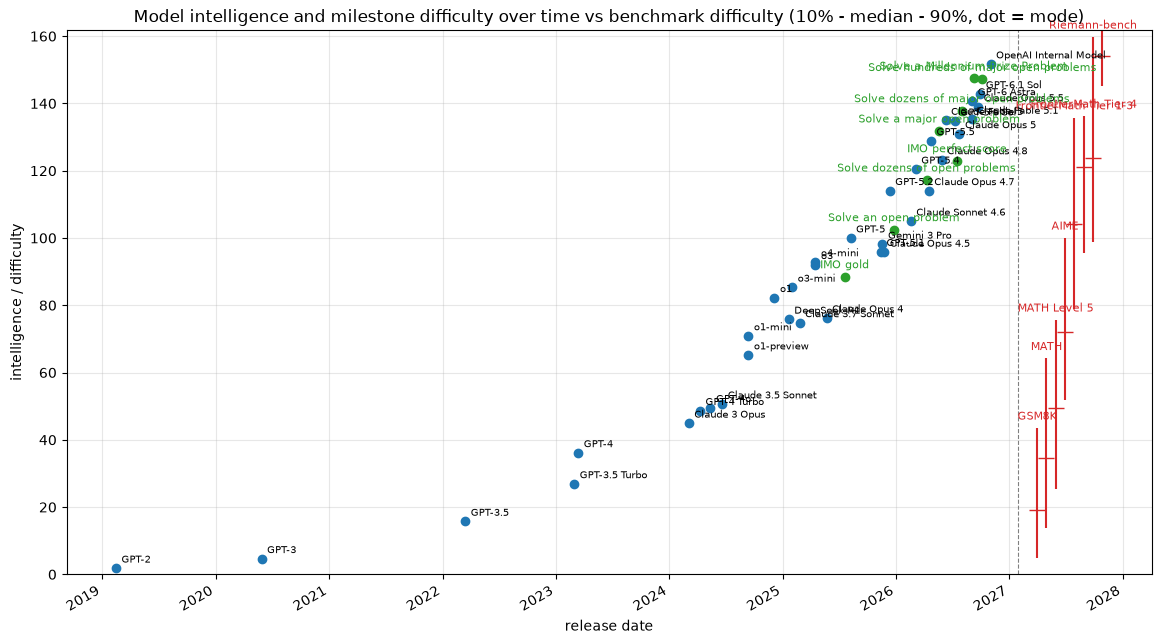

In [4]:
model_ids = list(data.models)
dates = [data.models[id].release_date for id in model_ids]
scores = [output.model_intelligences[id] for id in model_ids]

benchmark_ids = list(output.benchmark_difficulty_modes)
milestone_ids = list(output.milestone_difficulty_means)
benchmark_x0 = max(dates) + timedelta(days=150)

fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(dates, scores, 'o', color='tab:blue')

for id, x, y in zip(model_ids, dates, scores):
	ax.annotate(data.models[id].name, (x, y), textcoords='offset points', xytext=(4, 4), fontsize=7)

quantiles = torch.tensor([0.1, 0.5, 0.9])
benchmark_medians = []

for i, id in enumerate(benchmark_ids):
	mode = torch.tensor(output.benchmark_difficulty_modes[id])
	low_std = torch.tensor(output.benchmark_difficulty_low_stds[id])
	high_std = torch.tensor(output.benchmark_difficulty_high_stds[id])
	low, median, high = inverse_cumulative_split_normal(quantiles, mode, low_std, high_std).tolist()
	benchmark_medians.append(median)
	x = benchmark_x0 + timedelta(days=30 * i)

	ax.vlines(x, low, high, color='tab:red', linewidth=1.5)
	ax.plot([x], [median], marker='_', markersize=12, color='tab:red')
	ax.annotate(data.benchmarks[id].name, (x, high), textcoords='offset points', xytext=(0, 6), fontsize=8, color='tab:red', ha='center')

for id in milestone_ids:
	difficulty = output.milestone_difficulty_means[id]
	x = data.milestones[id].date_first

	ax.plot([x], [difficulty], marker='o', markersize=6, color='tab:green')
	ax.annotate(data.milestones[id].name, (x, difficulty), textcoords='offset points', xytext=(0, 6), fontsize=8, color='tab:green', ha='center')

ax.axvline(max(dates) + timedelta(days=90), color='gray', linestyle='--', linewidth=0.8)

ax.set_xlabel('release date')
ax.set_ylabel('intelligence / difficulty')
ax.set_title('Model intelligence and milestone difficulty over time vs benchmark difficulty (10% - median - 90%, dot = mode)')
ax.set_ylim(0, max(scores) + 10)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

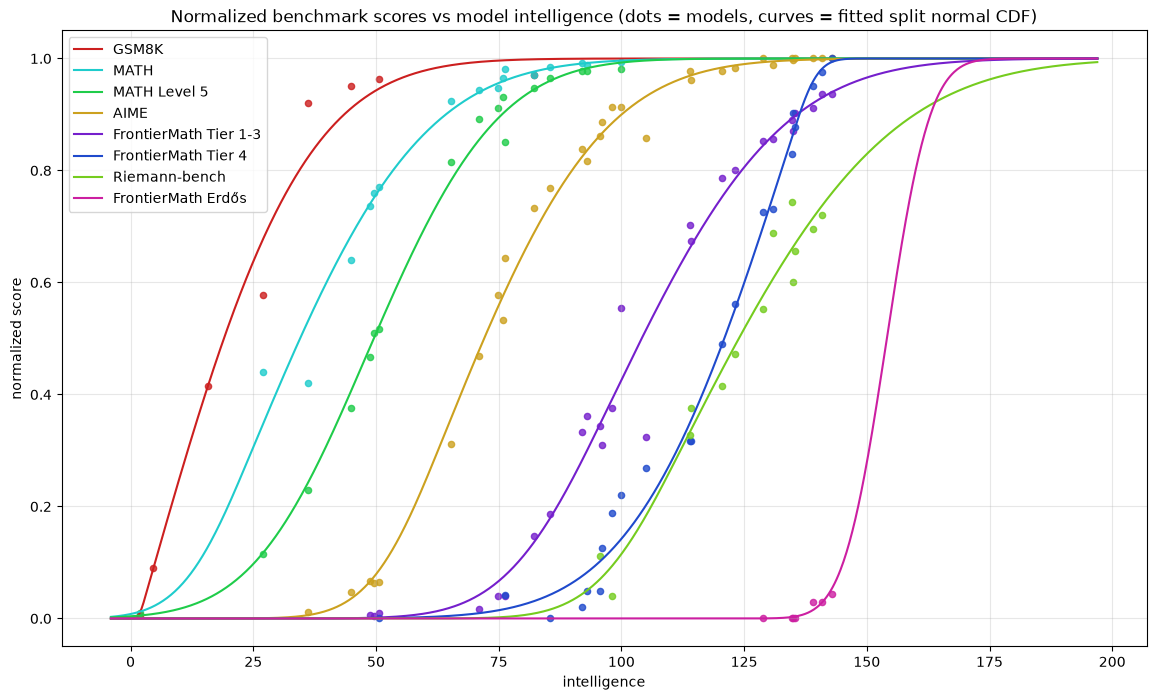

In [5]:
benchmark_ids = list(output.benchmark_difficulty_modes)
hues = [i / len(benchmark_ids) for i in range(len(benchmark_ids))]
random.shuffle(hues)

curve_bounds = []

for id in benchmark_ids:
	mode = torch.tensor(output.benchmark_difficulty_modes[id])
	low_std = torch.tensor(output.benchmark_difficulty_low_stds[id])
	high_std = torch.tensor(output.benchmark_difficulty_high_stds[id])
	curve_bounds += inverse_cumulative_split_normal(torch.tensor([0.01, 0.99]), mode, low_std, high_std).tolist()

intelligences = list(output.model_intelligences.values())
xs = torch.linspace(min(intelligences + curve_bounds) - 5, max(intelligences + curve_bounds) + 5, 1000)

fig, ax = plt.subplots(figsize=(14, 8))

for id, hue in zip(benchmark_ids, hues):
	color = colorsys.hsv_to_rgb(hue, 0.85, 0.8)
	mode = torch.tensor(output.benchmark_difficulty_modes[id])
	low_std = torch.tensor(output.benchmark_difficulty_low_stds[id])
	high_std = torch.tensor(output.benchmark_difficulty_high_stds[id])
	results = data.benchmarks[id].get_normalized_results()

	ax.plot(xs, cumulative_split_normal(xs, mode, low_std, high_std), color=color, linewidth=1.5, label=data.benchmarks[id].name)
	ax.scatter(
		[output.model_intelligences[model_id] for _, model_id, _ in results],
		[score for _, _, score in results],
		color=color, s=20, alpha=0.8,
	)

ax.set_xlabel('intelligence')
ax.set_ylabel('normalized score')
ax.set_title('Normalized benchmark scores vs model intelligence (dots = models, curves = fitted split normal CDF)')
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

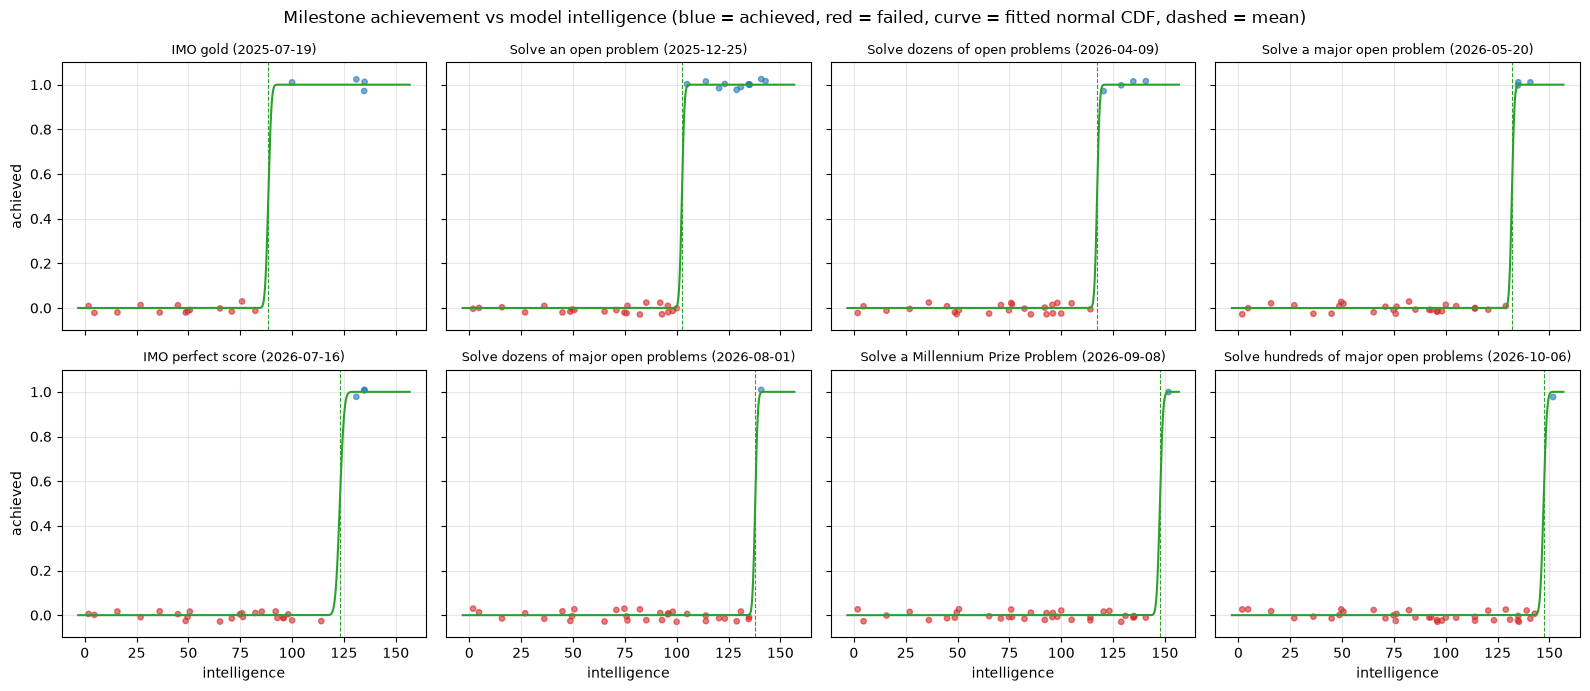

In [6]:
milestone_ids = list(output.milestone_difficulty_means)
milestone_results = data.get_milestone_results()

intelligences = list(output.model_intelligences.values())
xs = torch.linspace(min(intelligences) - 5, max(intelligences) + 5, 1000)

n_cols = 4
n_rows = math.ceil(len(milestone_ids) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows), sharex=True, sharey=True, squeeze=False)

for ax, id in zip(axes.flat, milestone_ids):
	mean = torch.tensor(output.milestone_difficulty_means[id])
	std = torch.tensor(output.milestone_difficulty_stds[id])
	results = [(model_id, score) for milestone_id, model_id, score in milestone_results if milestone_id == id]
	jitter = [random.uniform(-0.03, 0.03) for _ in results]

	ax.plot(xs, cumulative_normal(xs, mean, std), color='tab:green', linewidth=1.5)
	ax.axvline(mean.item(), color='tab:green', linestyle='--', linewidth=0.8)
	ax.scatter(
		[output.model_intelligences[model_id] for model_id, _ in results],
		[score + j for (_, score), j in zip(results, jitter)],
		c=['tab:blue' if score == 1.0 else 'tab:red' for _, score in results], s=15, alpha=0.6,
	)

	ax.set_title(f'{data.milestones[id].name} ({data.milestones[id].date_first})', fontsize=9)
	ax.set_ylim(-0.1, 1.1)
	ax.grid(alpha=0.3)

for ax in axes.flat[len(milestone_ids):]:
	ax.axis('off')

for ax in axes.flat[max(0, len(milestone_ids) - n_cols):len(milestone_ids)]:
	ax.xaxis.set_tick_params(labelbottom=True)
	ax.set_xlabel('intelligence')

for ax in axes[:, 0]:
	ax.set_ylabel('achieved')

fig.suptitle('Milestone achievement vs model intelligence (blue = achieved, red = failed, curve = fitted normal CDF, dashed = mean)')
fig.tight_layout()
plt.show()